# 01 Dataset exploration: DAIC-WOZ and E-DAIC

Supplementary material for Paper 1. Runs in Google Colab with Google Drive mounted.

Part A characterizes the cohorts (dataset table and figures of the paper). Part B recomputes the exploratory analyses of
the dissertation (Empath ANOVA, absolutist terms, feature correlations, DSM-5 criterion directions) **on the training split only**.

Only aggregates are written, to `results/eda/`. Do not add cells that print transcript text or per-participant rows:
the corpora are under EULA.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, sys
REPO = '/content/drive/MyDrive/05_Mestrado/Repositórios/depression-gnn-local/depression-gnn'
os.environ['DAIC_DATA_DIR'] = '/content/drive/MyDrive/Colab Notebooks/datasets'
os.chdir(REPO)
sys.path.insert(0, REPO)
!pip install -q empath pytest

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 kB 579.8 kB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


## Tests on synthetic data
No corpus data is read here.

In [3]:
!python -m pytest -q tests/test_eda.py tests/test_features_graph.py

.................                                                        [100%]
17 passed in 27.36s


## Part A: cohort characteristics

In [4]:
from pathlib import Path
from IPython.display import Image, display
from src.common import data, eda

OUT = Path('results/eda')
summary = eda.run_eda(data.data_root(), OUT)
summary

,DAIC-WOZ train,DAIC-WOZ dev,DAIC-WOZ test,E-DAIC
labeled sessions,107,35,47,112
sessions with transcript,107,33,46,112
depressed (PHQ-8 >= 10),30 (28.0%),12 (36.4%),14 (30.4%),34 (30.4%)
PHQ-8 mean (SD),6.4 (5.5),7.6 (6.7),7.1 (6.5),6.8 (6.5)
item scores available,False,True,False,True
Gender coded 0 / 1,44 / 63,17 / 16,24 / 22,n/a
"participant turns, median [IQR]",146 [113-188],177 [121-231],166 [132-242],96 [76-120]
"words, median [IQR]",1183 [781-1718],1389 [1049-1864],1419 [988-2140],1280 [856-1734]
"speech minutes, median [IQR]",7 [4-9],7 [5-11],8 [6-10],11 [7-19]
sessions with >= 1 tag (%),100.0,100.0,100.0,0.0


fig_phq8_distribution


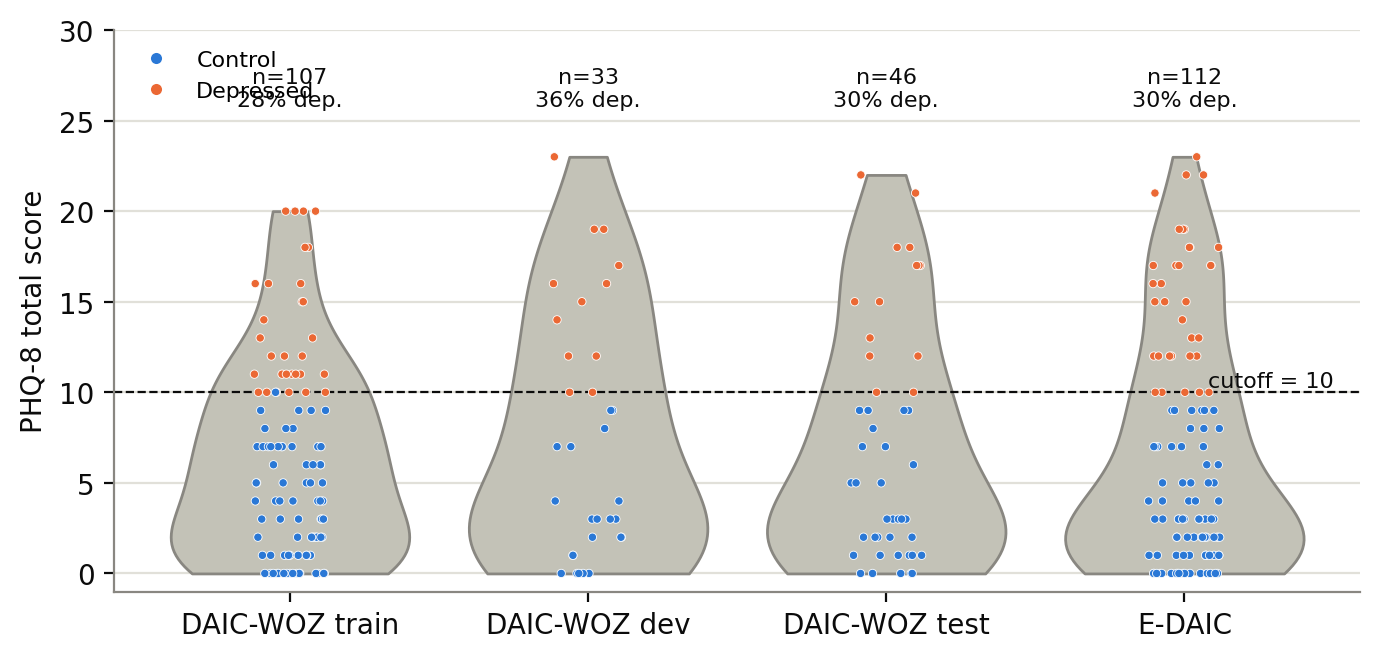

fig_phq8_item_profile


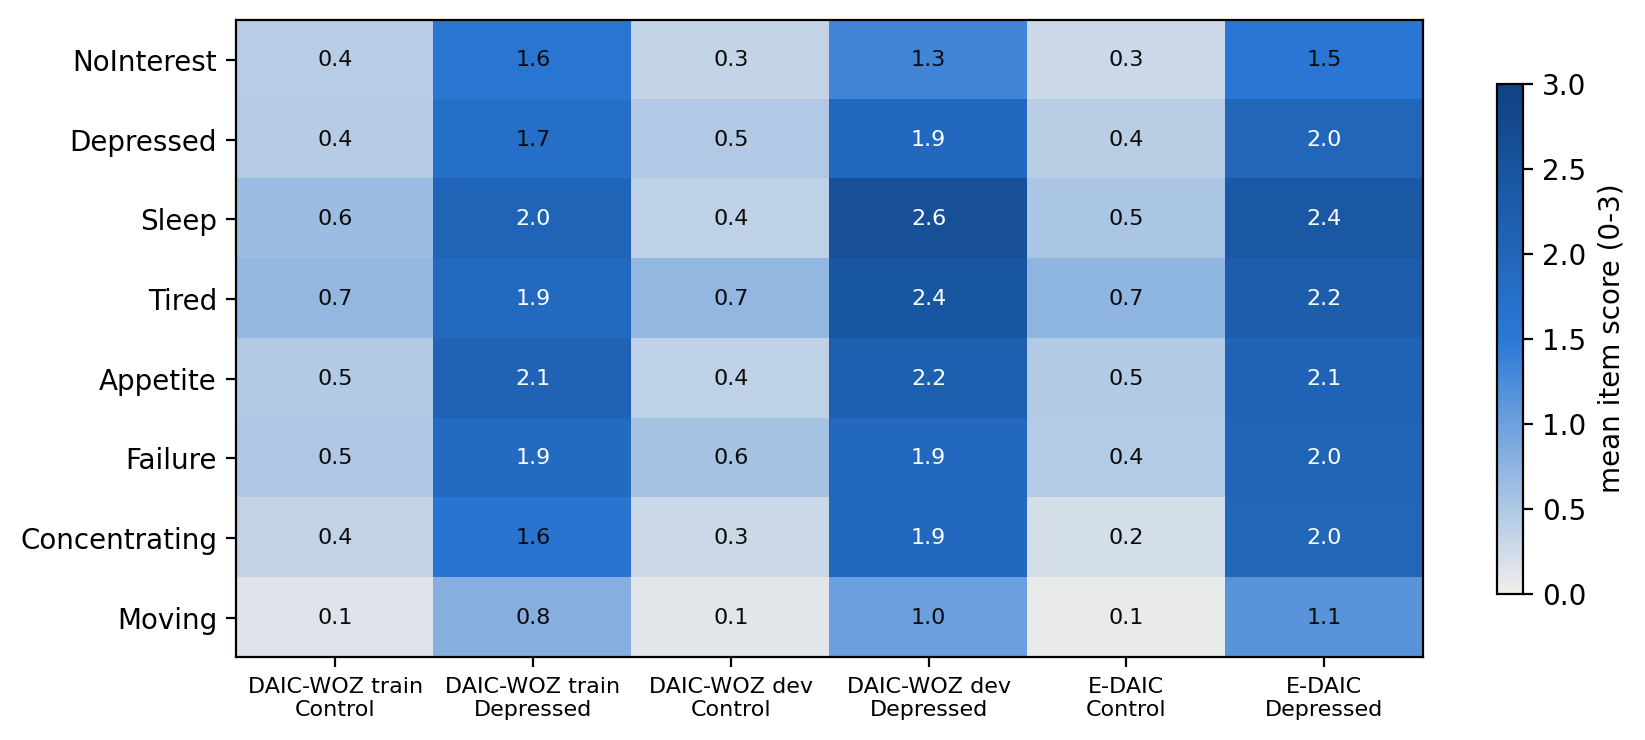

fig_phq8_item_correlation


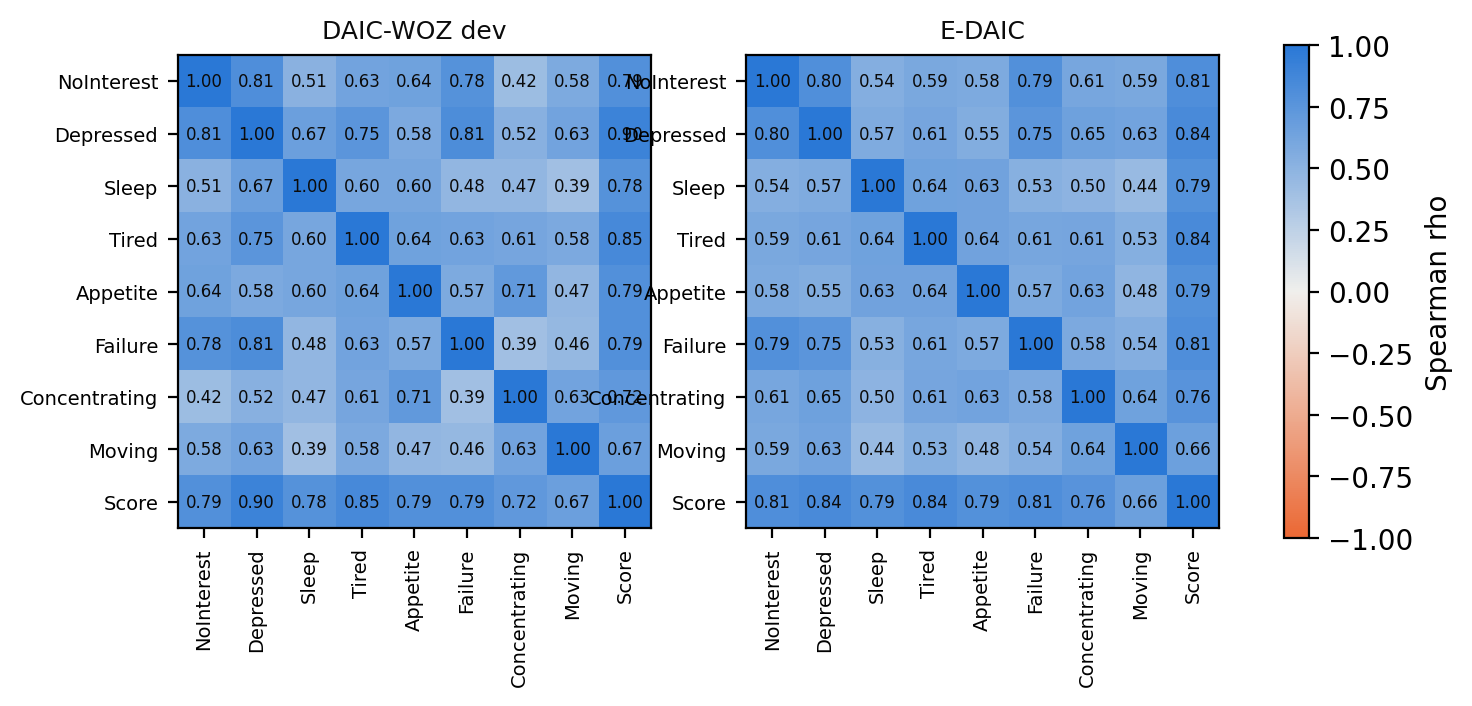

fig_session_length


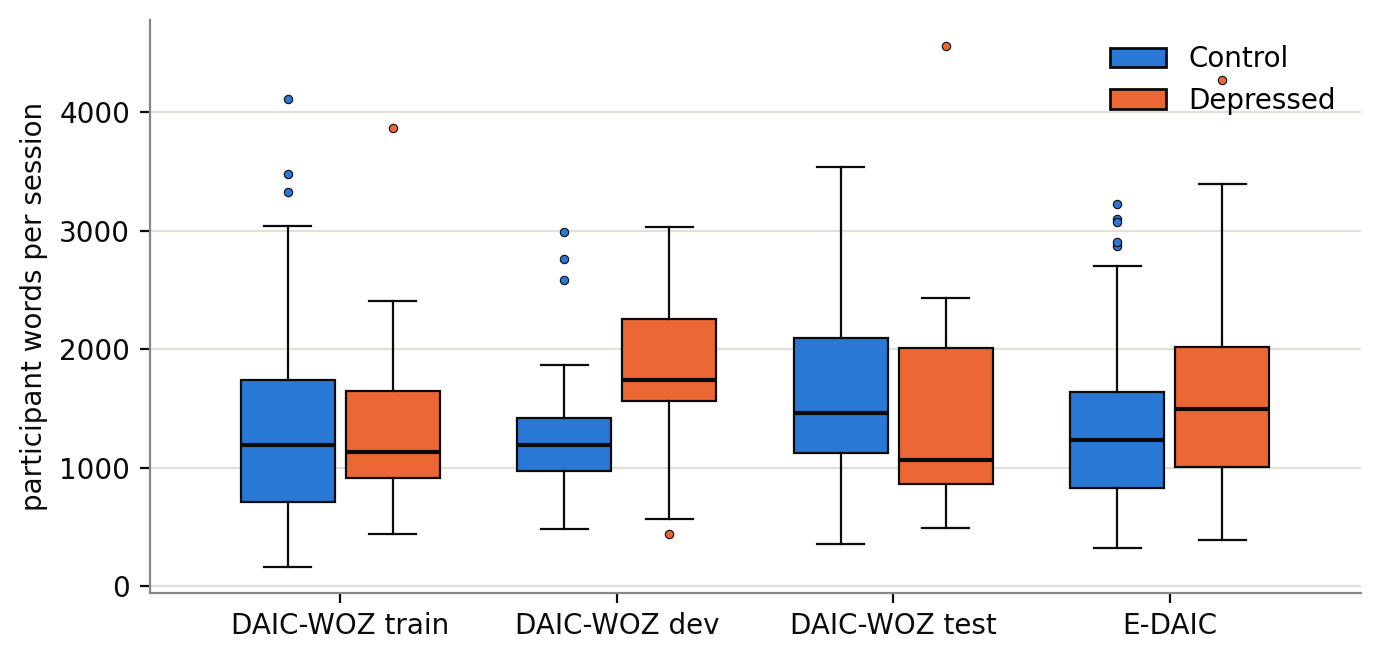

fig_transcript_quality


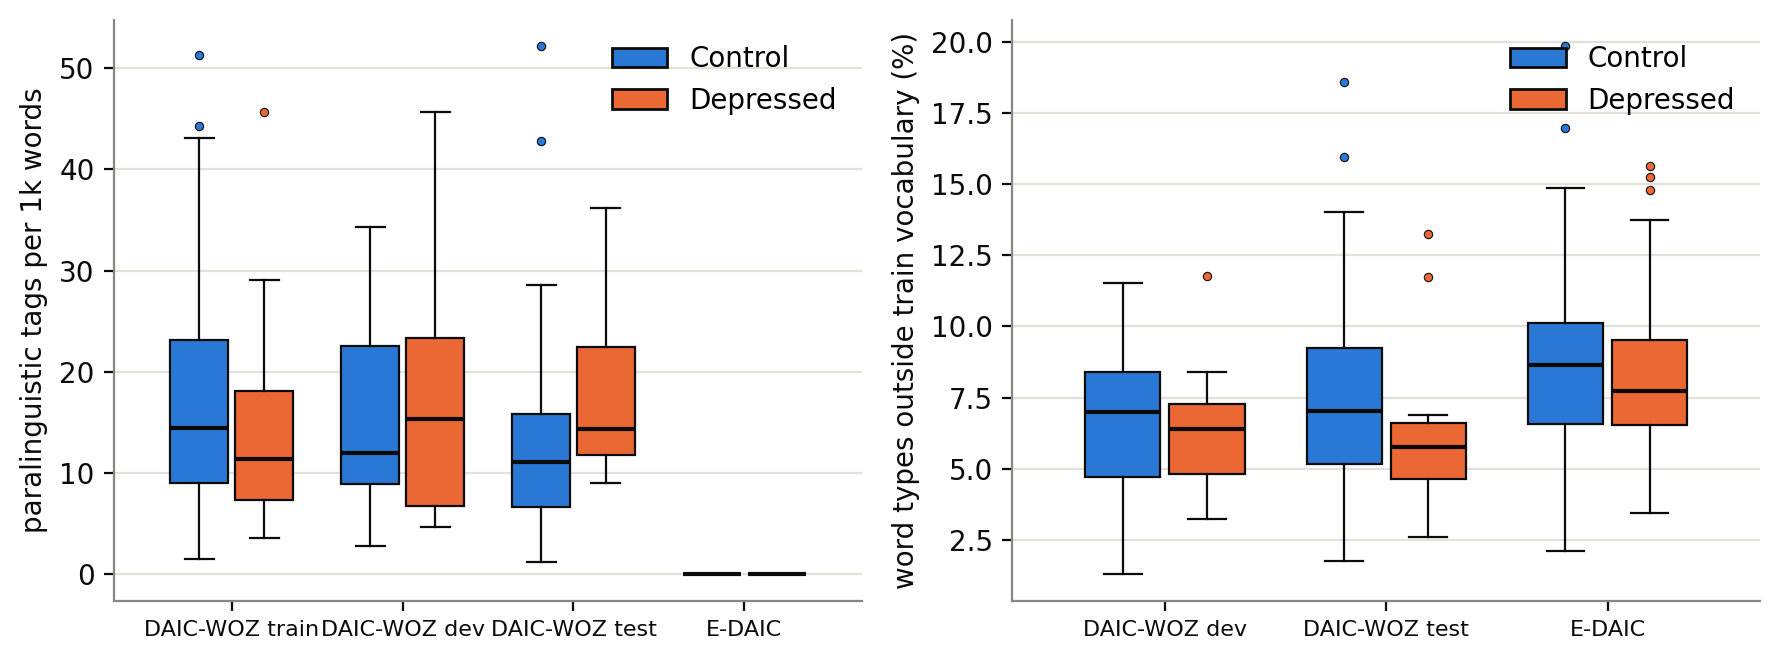

In [5]:
for name in eda.FIGURES:
    print(name)
    display(Image(filename=str(OUT / f'{name}.png'), width=720))

In [6]:
# PHQ-8 item difference (depressed minus control), dissertation Table 'phq8-delta-item'
import pandas as pd
sessions = eda.build_session_table(data.data_root())
sessions = sessions[sessions['transcript_available']]
delta = {}
for cohort in ['DAIC-WOZ train', 'DAIC-WOZ dev', 'E-DAIC']:
    t = sessions[sessions['cohort'] == cohort]
    delta[cohort] = t[t['PHQ8_Binary'] == 1][data.PHQ8_ITEMS].mean() - t[t['PHQ8_Binary'] == 0][data.PHQ8_ITEMS].mean()
delta = pd.DataFrame(delta).round(3)
delta.to_csv(OUT / 'phq8_item_delta.csv')
delta

,DAIC-WOZ train,DAIC-WOZ dev,E-DAIC
PHQ8_NoInterest,1.138,1.000,1.247
PHQ8_Depressed,1.292,1.440,1.590
PHQ8_Sleep,1.398,2.202,1.857
PHQ8_Tired,1.199,1.702,1.505
PHQ8_Appetite,1.599,1.786,1.597
PHQ8_Failure,1.386,1.345,1.581
PHQ8_Concentrating,1.249,1.631,1.782
PHQ8_Moving,0.670,0.905,1.096


## Part B: exploratory analyses, training split only

In [7]:
import json
import pandas as pd
from src.common import exploratory as ex
from src.common.features import EmpathScorer, view_columns
from src.paper1_graph_model.corpus import build_cohorts

scorer = EmpathScorer()
cohorts = build_cohorts(data.data_root(), scorer, psycholinguistic='dsm5')
train = cohorts['daic_train']
print('training cohort:', len(train.y), 'participants,', int(train.y.sum()), 'depressed')

training cohort: 107 participants, 30 depressed


In [8]:
# Empath: ANOVA over the 194 categories (dissertation Fig. 17 / Table 14, there on pooled corpora)
anova = ex.empath_anova(train, scorer.categories)
anova.to_csv(OUT / 'empath_anova_train.csv', index=False)
fig = ex.fig_empath_anova(anova); fig.savefig(OUT / 'fig_empath_anova_train.pdf', bbox_inches='tight')
anova.head(20)

,category,F,p,mean_control,mean_depressed
0,health,19.976334,0.000020,0.002135,0.004881
1,white_collar_job,8.431919,0.004495,0.001902,0.003298
2,neglect,7.384565,0.007697,0.000671,0.001327
3,occupation,7.075569,0.009039,0.002957,0.004389
4,torment,6.696984,0.011024,0.000120,0.000369
5,healing,5.694025,0.018813,0.002535,0.003597
6,masculine,5.600328,0.019791,0.000980,0.000475
7,timidity,5.460801,0.021346,0.001412,0.002157
8,sadness,5.243492,0.024029,0.002917,0.004066
9,office,5.215435,0.024400,0.001121,0.001769


In [9]:
# Absolutist terms (dissertation Figs. 18-19)
abs_tests = ex.absolutist_tests(train)
(OUT / 'absolutist_tests_train.json').write_text(json.dumps(abs_tests, indent=2))
fig = ex.fig_absolutist(train); fig.savefig(OUT / 'fig_absolutist_train.pdf', bbox_inches='tight')
abs_tests

{'n': 107,
 'median_control': 0.007052186177715092,
 'median_depressed': 0.007403859428367883,
 'mannwhitney_U': 1102.0,
 'mannwhitney_p_one_sided': 0.6446979777401205,
 'spearman_rho_phq8': -0.05302837899134429,
 'spearman_p': 0.5874954838307993}

In [10]:
# Professional features vs. PHQ-8 total
cols = view_columns(train.features, ('temporal', 'paralinguistic', 'psycholinguistic'))
corr = ex.feature_correlations(train, cols)
corr.to_csv(OUT / 'feature_correlations_train.csv', index=False)
fig = ex.fig_rho_bars(corr, 'feature'); fig.savefig(OUT / 'fig_feature_correlations_train.pdf', bbox_inches='tight')
corr

,feature,rho,p,n
0,dsm_C5,0.379657,0.000055,107
1,dsm_C4,0.358539,0.000149,107
2,dsm_C1,0.293044,0.002190,107
3,tag_breath,0.250315,0.009311,107
4,dsm_C6,0.245269,0.010887,107
5,latency,0.228969,0.017680,107
6,dsm_C7,0.193093,0.046293,107
7,tag_stress,-0.112128,0.250197,107
8,speech_min,-0.107128,0.272077,107
9,silence_speech,0.098905,0.310798,107


In [11]:
# DSM-5 criterion scores: does each move in the expected direction?
items = sessions[sessions['cohort'] == 'DAIC-WOZ train'].set_index('Participant_ID')[data.PHQ8_ITEMS]
direction = ex.criterion_direction(train, items)
direction.to_csv(OUT / 'dsm5_criterion_direction_train.csv', index=False)
fig = ex.fig_rho_bars(direction.assign(name=direction['criterion'] + ' ' + direction['label']), 'name', 'rho_total')
fig.savefig(OUT / 'fig_dsm5_criterion_direction_train.pdf', bbox_inches='tight')
direction

,criterion,label,rho_total,p_total,phq8_item,rho_item,p_item,direction_as_expected
0,C1,Depressed mood,0.293044,0.002190,PHQ8_Depressed,0.365478,0.000108,True
1,C2,Anhedonia,-0.015014,0.878008,PHQ8_NoInterest,-0.026602,0.785631,False
2,C3,Appetite change,-0.015941,0.870545,PHQ8_Appetite,0.017051,0.861618,False
3,C4,Sleep disturbance,0.358539,0.000149,PHQ8_Sleep,0.259186,0.007300,True
4,C5,Fatigue or loss of energy,0.379657,0.000055,PHQ8_Tired,0.284872,0.002939,True
5,C6,Worthlessness or guilt,0.245269,0.010887,PHQ8_Failure,0.205987,0.033287,True
6,C7,Diminished concentration,0.193093,0.046293,PHQ8_Concentrating,0.306120,0.001343,True
7,C8,Psychomotor retardation or agitation,0.008671,0.929369,PHQ8_Moving,0.079601,0.415059,True


## Part C: DSM-5 criterion reference profile (for per-case audit reports)

Mean and standard deviation of each criterion score by class on the training pool (DAIC-WOZ train + dev), written to
`results/eda/`. The criterion scores of the test participants are written to `OUTPUT_DIR`, outside the repository.

In [12]:
import numpy as np
OUTPUT_DIR = '/content/drive/MyDrive/Colab Notebooks/outputs/paper1/v2'   # outside the repository
os.makedirs(OUTPUT_DIR, exist_ok=True)
crit_cols = [c for c in cohorts['daic_train'].features.columns if c.startswith('dsm_')] + ['absolutist_rate']

pool_parts = [cohorts['daic_train'], cohorts['daic_dev']]
pool_feats = pd.concat([c.features.loc[c.ids, crit_cols] for c in pool_parts])
pool_y = np.concatenate([c.y for c in pool_parts])
reference = pd.DataFrame({
    'control_mean': pool_feats[pool_y == 0].mean(), 'control_sd': pool_feats[pool_y == 0].std(),
    'depressed_mean': pool_feats[pool_y == 1].mean(), 'depressed_sd': pool_feats[pool_y == 1].std(),
})
reference.to_csv(OUT / 'dsm5_reference_pool.csv')

test_c = cohorts['daic_test']
test_c.features.loc[test_c.ids, crit_cols].to_csv(f'{OUTPUT_DIR}/criterion_scores_daic_test.csv')
reference

,control_mean,control_sd,depressed_mean,depressed_sd
dsm_C1,0.003635,0.001726,0.004442,0.001975
dsm_C2,-0.004831,0.001806,-0.004481,0.001697
dsm_C3,0.001541,0.001064,0.001502,0.000902
dsm_C4,0.003018,0.001776,0.004462,0.001932
dsm_C5,0.001255,0.001480,0.002420,0.001692
dsm_C6,0.002904,0.003403,0.004222,0.002954
dsm_C7,-0.001450,0.002833,-0.000976,0.002645
dsm_C8,0.002484,0.001864,0.002401,0.002144
absolutist_rate,0.007704,0.004353,0.008324,0.004275


### Self-report vs. discourse, per DSM-5 criterion (training pool)

For each criterion, class separation (rank-biserial r, depressed vs. control) of the self-reported PHQ-8 item and of the
language criterion score. The item separation is large by construction (the label is a sum of items) and serves as a
ceiling; the distance to the language score shows how much of each symptom surfaces in what participants say.

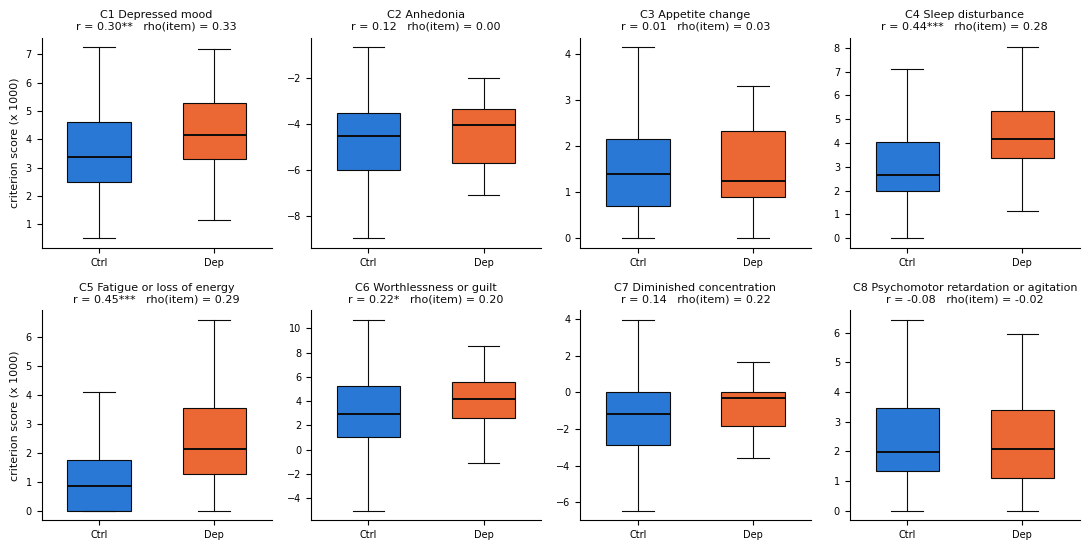

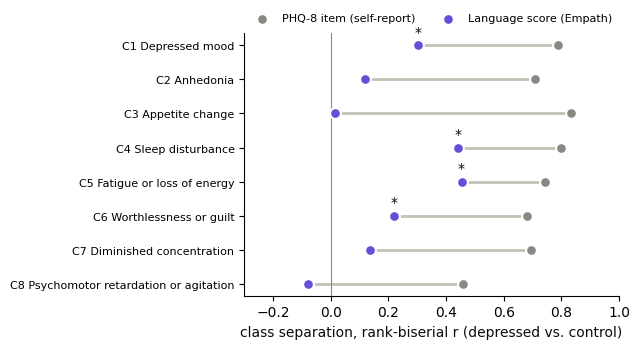

,criterion,label,phq8_item,r_item,p_item,r_language,p_language,gap,rho_language_item,p_rho
0,C1,Depressed mood,PHQ8_Depressed,0.787,0.0,0.302,0.005,0.486,0.329,0.000
1,C2,Anhedonia,PHQ8_NoInterest,0.710,0.0,0.119,0.266,0.591,0.001,0.993
2,C3,Appetite change,PHQ8_Appetite,0.835,0.0,0.014,0.897,0.821,0.032,0.703
3,C4,Sleep disturbance,PHQ8_Sleep,0.798,0.0,0.442,0.000,0.356,0.284,0.001
4,C5,Fatigue or loss of energy,PHQ8_Tired,0.743,0.0,0.454,0.000,0.289,0.292,0.000
5,C6,Worthlessness or guilt,PHQ8_Failure,0.681,0.0,0.221,0.039,0.460,0.199,0.018
6,C7,Diminished concentration,PHQ8_Concentrating,0.694,0.0,0.136,0.202,0.558,0.215,0.011
7,C8,Psychomotor retardation or agitation,PHQ8_Moving,0.460,0.0,-0.078,0.469,0.538,-0.025,0.772


In [13]:
from src.common import exploratory as ex
from IPython.display import display

items_all = eda.build_session_table(data.data_root())
items_all = items_all[items_all['cohort'].isin(['DAIC-WOZ train', 'DAIC-WOZ dev'])].set_index('Participant_ID')[data.PHQ8_ITEMS]
pool_ids = np.concatenate([c.ids for c in pool_parts])

contrast = ex.criterion_contrast(pool_feats.loc[pool_ids], pool_y, items_all.loc[pool_ids])
contrast.to_csv(OUT / 'dsm5_report_vs_discourse_pool.csv', index=False)
for name, fig in [('fig_dsm5_criteria_by_class_pool', ex.fig_criterion_by_class(pool_feats.loc[pool_ids], pool_y, contrast)),
                  ('fig_dsm5_report_vs_discourse_pool', ex.fig_report_vs_discourse(contrast))]:
    fig.savefig(OUT / f'{name}.pdf', bbox_inches='tight')
    fig.savefig(OUT / f'{name}.png', dpi=200, bbox_inches='tight')
    display(fig)
contrast.round(3)